# AI Smart Waste Classifier — Advanced Computer Vision Capstone

**Goal:** Train and deploy an image classifier that recognises six waste categories: cardboard, glass, metal, paper, plastic and trash.

**Model:** MobileNetV2 transfer learning, followed by fine-tuning.

**Deliverables:** trained Keras model, test metrics, confusion matrix, training curves, Grad-CAM visual explanation, and Gradio web application.

## Kaggle setup
1. Add a six-class Garbage Classification image dataset using **Add Input**.
2. Enable Internet in Notebook options so TensorFlow can download MobileNetV2 ImageNet weights.
3. Select a GPU accelerator if available.
4. Run all cells from top to bottom.

The notebook searches `/kaggle/input` for folders named like the six target classes. It supports common folder layouts such as `.../Garbage classification/cardboard/` and `.../train/cardboard/`.

**Important:** This is a learning prototype. It classifies the visible image; it cannot determine local recycling rules, material composition, contamination, or whether an item is accepted by a particular waste facility. Treat its disposal suggestions as general guidance, not authoritative instructions.

In [1]:
# 1. Install and import dependencies
%pip -q install gradio scikit-learn seaborn

import os, random, json, shutil, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Note: you may need to restart the kernel to use updated packages.
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# 2. Configuration
from pathlib import Path

DATA_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/waste_classifier")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
INITIAL_EPOCHS = 12
FINE_TUNE_EPOCHS = 8
AUTOTUNE = tf.data.AUTOTUNE

CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Target classes:", CLASS_NAMES)
print("Output directory:", OUTPUT_DIR)

Target classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Output directory: /kaggle/working/waste_classifier


In [3]:
# 3. Discover the six class folders in Kaggle Input
# Your attached dataset is nested:
# /kaggle/input/garbage-classification/Garbage classification/Garbage classification/
#     cardboard/ glass/ metal/ paper/ plastic/ trash/

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_count(folder):
    folder = Path(folder)
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

# Search every directory and score it by how many expected class folders it contains.
# This handles nested folders and common Kaggle dataset layouts.
expected_aliases = {
    "cardboard": {"cardboard", "carton"},
    "glass": {"glass"},
    "metal": {"metal"},
    "paper": {"paper"},
    "plastic": {"plastic"},
    "trash": {"trash", "garbage"}
}

candidate_roots = []
for current, dirs, files in os.walk("/kaggle/input"):
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    current_path = Path(current)
    child_names = {d.lower().strip(): current_path / d for d in dirs}

    found_classes = {}
    for canonical, aliases in expected_aliases.items():
        for alias in aliases:
            if alias in child_names:
                class_folder = child_names[alias]
                n_images = image_count(class_folder)
                if n_images > 0:
                    found_classes[canonical] = (class_folder, n_images)
                    break

    if len(found_classes) >= 2:
        total_images = sum(v[1] for v in found_classes.values())
        candidate_roots.append({
            "root": current_path,
            "classes": found_classes,
            "class_count": len(found_classes),
            "image_count": total_images
        })

candidate_roots.sort(
    key=lambda x: (x["class_count"], x["image_count"]),
    reverse=True
)

print("Dataset directory candidates:")
for candidate in candidate_roots[:10]:
    print(
        f"{candidate['root']} | "
        f"{candidate['class_count']} classes | "
        f"{candidate['image_count']} images"
    )

if not candidate_roots:
    raise FileNotFoundError(
        "Could not locate waste category folders. Confirm the Garbage Classification "
        "dataset is attached in Kaggle's Input panel."
    )

# Select the directory containing the most expected classes and images.
best_candidate = candidate_roots[0]
DATASET_DIR = str(best_candidate["root"])
print("\nSelected dataset root:", DATASET_DIR)
print("Detected categories:", list(best_candidate["classes"].keys()))

# Build the manifest from the selected class folders.
CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

records = []
for class_name in CLASS_NAMES:
    if class_name not in best_candidate["classes"]:
        continue

    class_folder = best_candidate["classes"][class_name][0]
    for image_path in class_folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(image_path),
                "label": class_name,
                "label_id": CLASS_TO_INDEX[class_name]
            })

data_df = (
    pd.DataFrame(records)
    .drop_duplicates(subset=["filepath"])
    .reset_index(drop=True)
)

print("\nMatched class folders:")
display(
    data_df.groupby("label")
    .size()
    .reindex(CLASS_NAMES, fill_value=0)
    .rename("image_count")
    .to_frame()
)

missing_classes = [
    name for name in CLASS_NAMES
    if name not in set(data_df["label"].unique())
]
if missing_classes:
    raise ValueError(
        f"Missing categories: {missing_classes}. "
        "The selected dataset must contain all six classes."
    )

if len(data_df) < 60:
    raise ValueError(
        f"Only {len(data_df)} images were found. More labelled images are needed "
        "for a meaningful train/validation/test split."
    )

print("\nSUCCESS: dataset loaded.")
print("Total images:", len(data_df))
print("Dataset root:", DATASET_DIR)

Dataset directory candidates:
/kaggle/input/datasets/asdasdasasdas/garbage-classification/Garbage classification/Garbage classification | 6 classes | 2527 images
/kaggle/input/datasets/asdasdasasdas/garbage-classification/garbage classification/Garbage classification | 6 classes | 2527 images

Selected dataset root: /kaggle/input/datasets/asdasdasasdas/garbage-classification/Garbage classification/Garbage classification
Detected categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

Matched class folders:


,image_count
label,
cardboard,403
glass,501
metal,410
paper,594
plastic,482
trash,137



SUCCESS: dataset loaded.
Total images: 2527
Dataset root: /kaggle/input/datasets/asdasdasasdas/garbage-classification/Garbage classification/Garbage classification


Dataset root: /kaggle/input/datasets/asdasdasasdas/garbage-classification/Garbage classification/Garbage classification
Number of image files: 2527

Class distribution:


,images
label,
cardboard,403
glass,501
metal,410
paper,594
plastic,482
trash,137


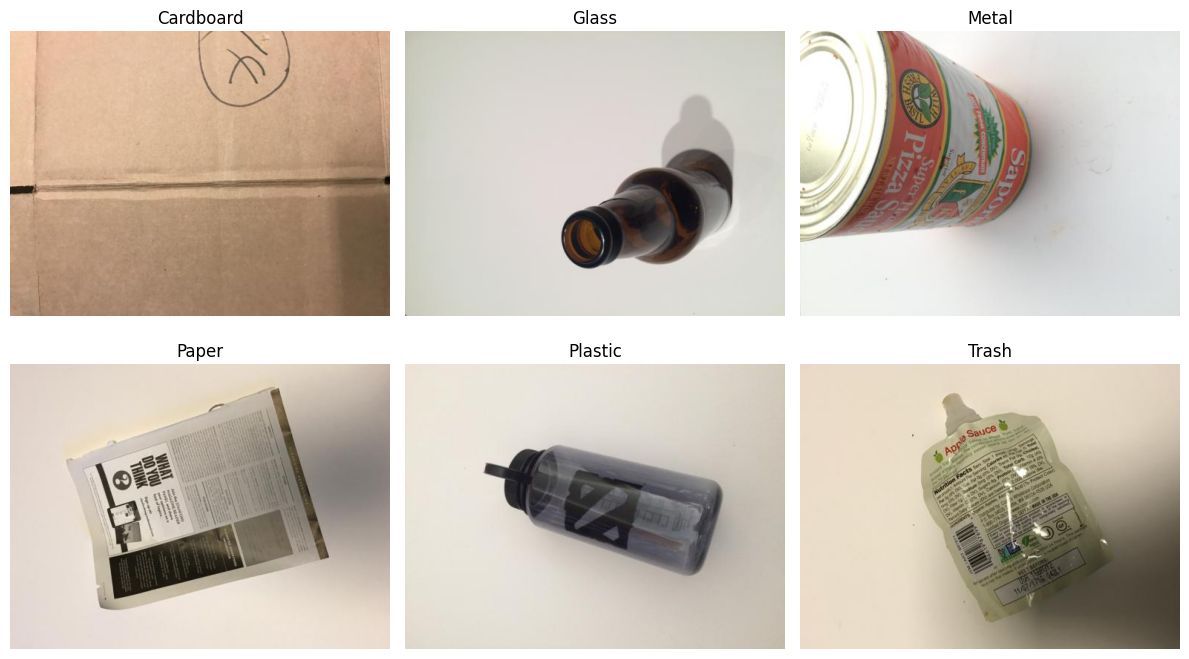

In [4]:
# 4. Dataset verification
print("Dataset root:", DATASET_DIR)
print("Number of image files:", len(data_df))
print("\nClass distribution:")
display(data_df["label"].value_counts().reindex(CLASS_NAMES).rename("images").to_frame())

# Show one example image from each class.
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, class_name in zip(axes.flat, CLASS_NAMES):
    sample_path = data_df.loc[
        data_df["label"] == class_name, "filepath"
    ].iloc[0]
    with Image.open(sample_path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(class_name.title())
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# 5. Stratified train / validation / test split (70% / 15% / 15%)
train_df, temp_df = train_test_split(
    data_df,
    test_size=0.30,
    random_state=SEED,
    stratify=data_df["label_id"]
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label_id"]
)

print(f"Train: {len(train_df)} ({len(train_df)/len(data_df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(data_df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(data_df):.1%})")

display(pd.DataFrame({
    "train": train_df["label"].value_counts().reindex(CLASS_NAMES),
    "validation": val_df["label"].value_counts().reindex(CLASS_NAMES),
    "test": test_df["label"].value_counts().reindex(CLASS_NAMES)
}).fillna(0).astype(int))

Train: 1768 (70.0%)
Validation: 379 (15.0%)
Test: 380 (15.0%)


,train,validation,test
label,,,
cardboard,282,61,60
glass,350,75,76
metal,287,61,62
paper,416,89,89
plastic,337,72,73
trash,96,21,20


In [6]:
# 6. Build efficient TensorFlow input pipelines
def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)  # keep 0..255 for MobileNetV2 preprocessing layer
    return image, label

def make_dataset(frame, training=False):
    paths = frame["filepath"].astype(str).values
    labels = frame["label_id"].astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Calculate class weights to reduce the effect of class imbalance.
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(sorted(train_df["label_id"].unique())),
    y=train_df["label_id"].values
)
CLASS_WEIGHTS = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        sorted(train_df["label_id"].unique()), weights
    )
}
print("Class weights:", CLASS_WEIGHTS)

Class weights: {0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}


In [7]:
# 7. Create MobileNetV2 transfer-learning model
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.12),
    tf.keras.layers.RandomContrast(0.10),
], name="data_augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(scale=1./127.5, offset=-1, name="mobilenet_preprocessing")(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax", name="predictions")(x)

model = tf.keras.Model(inputs, outputs, name="AI_Smart_Waste_Classifier")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "AI_Smart_Waste_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
# 8. Train classification head
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / "best_waste_classifier.keras"),
        monitor="val_accuracy",
        save_best_only=True
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=callbacks
)

Epoch 1/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.4734 - loss: 1.3946 - val_accuracy: 0.7018 - val_loss: 0.8388 - learning_rate: 0.0010
Epoch 2/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.7031 - loss: 0.8242 - val_accuracy: 0.7731 - val_loss: 0.6762 - learning_rate: 0.0010
Epoch 3/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.7443 - loss: 0.7093 - val_accuracy: 0.7942 - val_loss: 0.6295 - learning_rate: 0.0010
Epoch 4/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.7817 - loss: 0.6039 - val_accuracy: 0.8074 - val_loss: 0.5726 - learning_rate: 0.0010
Epoch 5/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.8049 - loss: 0.5513 - val_accuracy: 0.8047 - val_loss: 0.5900 - learning_rate: 0.0010
Epoch 6/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.8015 - loss: 0.5137 - val_accuracy: 0.8153 - val_loss: 0.5691 - learning_rate: 0.0010
Epoch 7/12
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.8235 - loss: 0.4921 - val_a

In [9]:
# 9. Fine-tune the final MobileNetV2 layers
base_model.trainable = True

# Unfreeze only the final 30 layers; keep Batch Normalization layers frozen.
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=callbacks
)

Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 12s 106ms/step - accuracy: 0.8512 - loss: 0.3856 - val_accuracy: 0.8285 - val_loss: 0.4855 - learning_rate: 1.0000e-05
Epoch 2/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.8705 - loss: 0.3535 - val_accuracy: 0.8364 - val_loss: 0.5021 - learning_rate: 1.0000e-05
Epoch 3/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.8807 - loss: 0.3154 - val_accuracy: 0.8311 - val_loss: 0.5261 - learning_rate: 1.0000e-05
Epoch 4/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.8954 - loss: 0.2841 - val_accuracy: 0.8470 - val_loss: 0.4732 - learning_rate: 3.0000e-06
Epoch 5/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9005 - loss: 0.2721 - val_accuracy: 0.8417 - val_loss: 0.4827 - learning_rate: 3.0000e-06
Epoch 6/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.8988 - loss: 0.2756 - val_accuracy: 0.8522 - val_loss: 0.4752 - learning_rate: 3.0000e-06
Epoch 7/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9055 - los

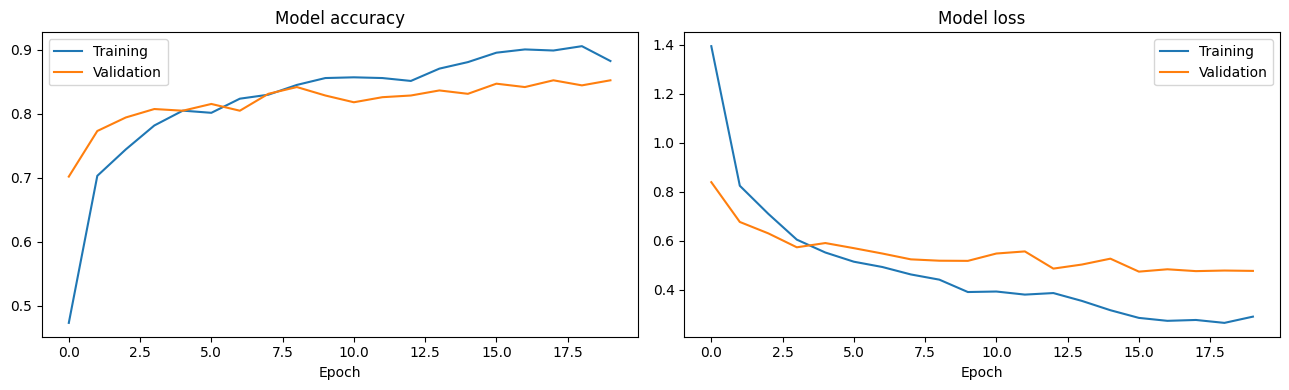

In [10]:
# 10. Plot training history
def combine_histories(*histories):
    combined = {}
    for h in histories:
        for key, values in h.history.items():
            combined.setdefault(key, []).extend(values)
    return combined

training_history = combine_histories(history_head, history_fine)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(training_history.get("accuracy", []), label="Training")
axes[0].plot(training_history.get("val_accuracy", []), label="Validation")
axes[0].set_title("Model accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(training_history.get("loss", []), label="Training")
axes[1].plot(training_history.get("val_loss", []), label="Validation")
axes[1].set_title("Model loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.8316 - loss: 0.4647
Test accuracy: 0.8316
Test loss: 0.4647
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step

Classification report:
              precision    recall  f1-score   support

   cardboard     0.8814    0.8667    0.8739        60
       glass     0.8182    0.8289    0.8235        76
       metal     0.7571    0.8548    0.8030        62
       paper     0.8764    0.8764    0.8764        89
     plastic     0.8169    0.7945    0.8056        73
       trash     0.8571    0.6000    0.7059        20

    accuracy                         0.8316       380
   macro avg     0.8345    0.8036    0.8147       380
weighted avg     0.8336    0.8316    0.8309       380



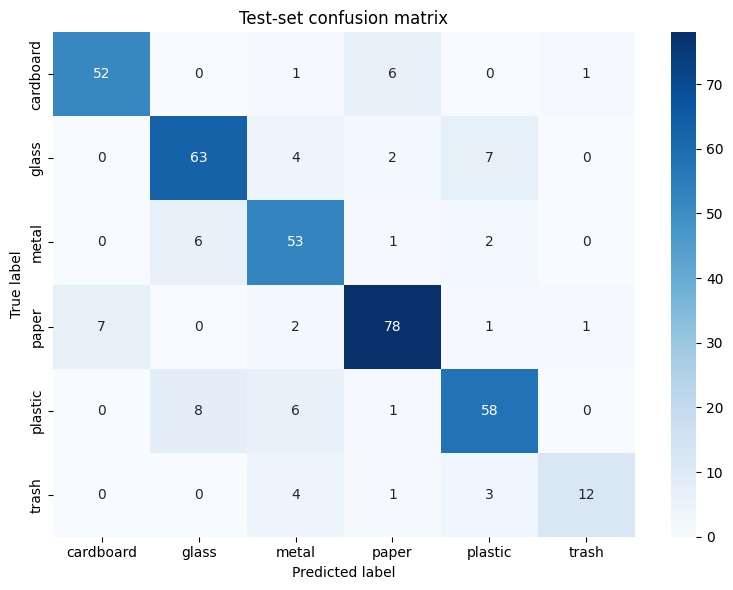

In [11]:
# 11. Final evaluation on held-out test data
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification report:")
report = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0
)
print(report)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

with open(OUTPUT_DIR / "classification_report.txt", "w") as f:
    f.write(report)
with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump({"test_accuracy": float(test_accuracy), "test_loss": float(test_loss)}, f, indent=2)

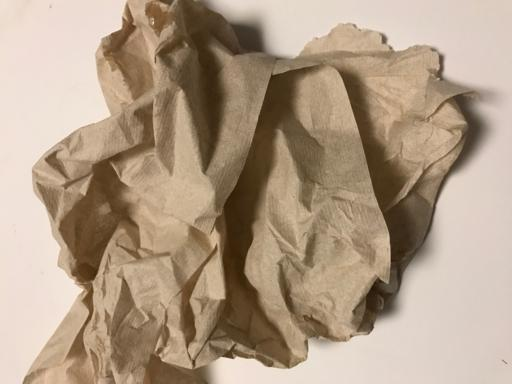

Actual class: trash
### Prediction: Trash
**Confidence:** 96.8%

**Disposal guidance:** This model predicts general trash; check whether the item belongs in residual waste or a special collection stream.
Scores: {'trash': 0.9681807160377502, 'paper': 0.020991472527384758, 'cardboard': 0.009033291600644588, 'metal': 0.0010700845159590244, 'plastic': 0.0006683163810521364, 'glass': 5.6219192629214376e-05}


In [12]:
# 12. Single-image prediction helper
DISPOSAL_GUIDANCE = {
    "cardboard": "Keep dry and clean; flatten boxes. Follow local paper/cardboard collection rules.",
    "glass": "Handle carefully. Separate by local glass collection rules; broken glass may need special handling.",
    "metal": "Empty and rinse containers where appropriate; follow local metal recycling rules.",
    "paper": "Keep clean and dry. Greasy or laminated paper may not be accepted with regular paper recycling.",
    "plastic": "Check the resin type and local acceptance rules. Empty and rinse containers where appropriate.",
    "trash": "This model predicts general trash; check whether the item belongs in residual waste or a special collection stream."
}

def predict_waste(image, confidence_threshold=0.55):
    if image is None:
        return None, "Please upload an image."

    image = image.convert("RGB").resize(IMG_SIZE)
    array = np.asarray(image, dtype=np.float32)
    probabilities = model.predict(np.expand_dims(array, axis=0), verbose=0)[0]

    best_idx = int(np.argmax(probabilities))
    best_class = CLASS_NAMES[best_idx]
    confidence = float(probabilities[best_idx])

    scores = {
        CLASS_NAMES[i]: float(probabilities[i])
        for i in range(len(CLASS_NAMES))
    }
    scores = dict(sorted(scores.items(), key=lambda item: item[1], reverse=True))

    if confidence < confidence_threshold:
        title = "### Low-confidence prediction"
        result = (
            f"{title}\nThe model is not sufficiently confident to classify this image. "
            f"Top guess: **{best_class.title()} ({confidence:.1%})**. "
            "Try a clearer, well-lit photo with one item visible."
        )
    else:
        result = (
            f"### Prediction: {best_class.title()}\n"
            f"**Confidence:** {confidence:.1%}\n\n"
            f"**Disposal guidance:** {DISPOSAL_GUIDANCE[best_class]}"
        )

    return scores, result

# Quick test using one held-out test image.
sample = test_df.sample(1, random_state=SEED).iloc[0]
sample_image = Image.open(sample["filepath"]).convert("RGB")
sample_scores, sample_result = predict_waste(sample_image)
display(sample_image)
print("Actual class:", sample["label"])
print(sample_result)
print("Scores:", sample_scores)

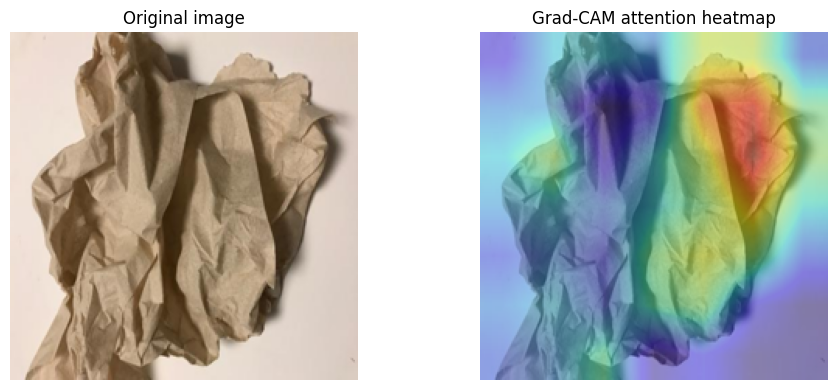

In [13]:
# 13. Grad-CAM visual explanation
# Grad-CAM highlights image regions that influenced the selected class score.

# Build an intermediate MobileNetV2 model that exposes the final convolutional feature map.
base_grad_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[base_model.get_layer("out_relu").output, base_model.output]
)

def make_gradcam_heatmap(pil_image, class_index=None):
    image = pil_image.convert("RGB").resize(IMG_SIZE)
    array = np.asarray(image, dtype=np.float32)
    input_tensor = tf.expand_dims(array, axis=0)

    with tf.GradientTape() as tape:
        augmented = model.get_layer("data_augmentation")(input_tensor, training=False)
        preprocessed = model.get_layer("mobilenet_preprocessing")(augmented)
        conv_outputs, base_features = base_grad_model(preprocessed, training=False)

        pooled = model.get_layer("global_average_pooling2d")(base_features)
        dropped = model.get_layer("dropout")(pooled, training=False)
        predictions = model.get_layer("predictions")(dropped)

        if class_index is None:
            class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def show_gradcam(pil_image):
    heatmap = make_gradcam_heatmap(pil_image)
    original = np.asarray(pil_image.convert("RGB").resize(IMG_SIZE))
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], IMG_SIZE
    ).numpy().squeeze()

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(original)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.40)
    plt.title("Grad-CAM attention heatmap")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

show_gradcam(sample_image)

In [14]:
# 14. Save model and class metadata
MODEL_PATH = OUTPUT_DIR / "ai_smart_waste_classifier.keras"
model.save(MODEL_PATH)

metadata = {
    "project": "AI Smart Waste Classifier",
    "architecture": "MobileNetV2 transfer learning + fine-tuning",
    "image_size": list(IMG_SIZE),
    "class_names": CLASS_NAMES,
    "seed": SEED,
    "test_accuracy": float(test_accuracy)
}
with open(OUTPUT_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", OUTPUT_DIR / "model_metadata.json")

Saved model: /kaggle/working/waste_classifier/ai_smart_waste_classifier.keras
Saved metadata: /kaggle/working/waste_classifier/model_metadata.json


In [15]:
# 15. Gradio web application
import gradio as gr

def gradio_predict(image):
    scores, explanation = predict_waste(image)
    return explanation, scores

with gr.Blocks(theme=gr.themes.Soft(), title="AI Smart Waste Classifier") as demo:
    gr.Markdown(
        "# ♻️ AI Smart Waste Classifier\n"
        "Upload a waste image to classify it into cardboard, glass, metal, paper, plastic or trash."
    )
    with gr.Row():
        with gr.Column():
            image_input = gr.Image(type="pil", label="Upload waste image")
            predict_button = gr.Button("Classify Waste", variant="primary")
        with gr.Column():
            prediction_text = gr.Markdown(label="Prediction")
            confidence_chart = gr.Label(num_top_classes=6, label="Class probabilities")

    predict_button.click(
        gradio_predict,
        inputs=image_input,
        outputs=[prediction_text, confidence_chart]
    )
    image_input.change(
        gradio_predict,
        inputs=image_input,
        outputs=[prediction_text, confidence_chart]
    )

print("Gradio app is ready.")

Gradio app is ready.


In [16]:
# 16. Launch the application
# Kaggle can create a temporary public URL with share=True.
try:
    demo.queue().launch(share=True, show_error=True)
except Exception as launch_error:
    print("Public sharing failed:", repr(launch_error))
    demo.queue().launch(share=False, show_error=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://8c3596cb6e2d973505.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [17]:
# 17. Package deliverables for download
zip_path = Path("/kaggle/working/AI_Smart_Waste_Classifier_Deliverables.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file_path in OUTPUT_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.relative_to(OUTPUT_DIR))

print("Deliverables ZIP:", zip_path)
print("Files in output folder:")
for file_path in OUTPUT_DIR.rglob("*"):
    if file_path.is_file():
        print(file_path, f"({file_path.stat().st_size/1024:.1f} KB)")

Deliverables ZIP: /kaggle/working/AI_Smart_Waste_Classifier_Deliverables.zip
Files in output folder:
/kaggle/working/waste_classifier/best_waste_classifier.keras (21309.8 KB)
/kaggle/working/waste_classifier/test_metrics.json (0.1 KB)
/kaggle/working/waste_classifier/classification_report.txt (0.5 KB)
/kaggle/working/waste_classifier/ai_smart_waste_classifier.keras (21309.8 KB)
/kaggle/working/waste_classifier/model_metadata.json (0.3 KB)


## 18. Capstone report and testing checklist

### Suggested report sections
1. **Problem statement:** Manual waste sorting is inconsistent; image classification can assist initial categorisation.
2. **Objective:** Build a six-class image classifier and an interactive demo.
3. **Dataset:** State the exact Kaggle dataset name, source, image count and class distribution used in your run.
4. **Methodology:** Image resizing, augmentation, MobileNetV2 transfer learning, class weighting and fine-tuning.
5. **Evaluation:** Report the measured held-out test accuracy, per-class precision/recall/F1 and confusion matrix. Do not invent or pre-fill scores.
6. **Explainability:** Include the Grad-CAM example and discuss whether the model focuses on the waste item rather than the background.
7. **Deployment:** Explain the Gradio upload/prediction interface.
8. **Limitations and future work:** More diverse images, real-world lighting, multiple objects, contamination detection, local recycling policy integration.

### Final testing checklist
- [ ] Dataset discovery found all six classes.
- [ ] Class counts and sample images were inspected.
- [ ] Train/validation/test split was stratified.
- [ ] Training and fine-tuning completed.
- [ ] Test metrics and confusion matrix were generated.
- [ ] At least one image from each class was tested.
- [ ] Low-confidence behaviour was checked.
- [ ] Grad-CAM visualisation was reviewed.
- [ ] Gradio application accepted an image and returned probabilities.
- [ ] Model and metadata files were saved.

### Important limitations
- A high test score does not guarantee real-world performance; test images may be similar to training images.
- The confidence score is not a calibrated probability of correctness.
- The model predicts one main category per image; it is not an object detector for multiple items.
- Glass subclasses are grouped into one glass class.
- Disposal guidance is generic and must be checked against local municipal rules.
- If the dataset folder names differ, update `CLASS_ALIASES` in Cell 2.

### References
- TensorFlow: https://www.tensorflow.org/
- Keras MobileNetV2: https://keras.io/api/applications/mobilenet/
- Gradio: https://www.gradio.app/docs
- scikit-learn metrics: https://scikit-learn.org/stable/modules/model_evaluation.html
